In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training,
                   run_training_loop, plot_training_log)

In [2]:
# ── What to train ─────────────────────────────────────────────────────────────
train_task = 'wn'

# Frequency grid context: includes all task types the animal may encounter,
# so the network learns to encode across the full frequency range.
task_list  = ['pure', 'harmonic', 'wn']

# ── Training schedule ────────────────────────────────────────────────────────
n_steps         = 15000   # total training batches
k               = 100     # evaluate and save every k batches
seed            = 0
eval_with_noise = True  # if True, evaluation also adds input noise

# ── Save location ────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir = str(RESULTS_DIR / train_task) + '/'

In [3]:
state, cfg = setup_training(train_task, task_list, n_steps, k, seed, save_dir)

task_list : ['pure', 'harmonic', 'wn']
train_task: wn
n_freq=50  n_in=54 (freq+fixation+context)  n_rnn=128  alpha=0.100
pulse_dur=50ms  n_pulses=8  stim_dur=400ms  tdim=240 (2400ms)
save_dir  : C:\Users\zhixi\Documents\GitHub\tone_generalize\code\results\wn\wn_0_lr5e-05_bs128_noise0.5_nrnn128


In [4]:
state, log = run_training_loop(state, train_task, task_list, cfg, eval_with_noise=eval_with_noise)

step    100  loss=0.2132  hit=0.01  FA=0.02
step    200  loss=0.2036  hit=0.02  FA=0.00
step    300  loss=0.2023  hit=0.04  FA=0.01
step    400  loss=0.1916  hit=0.03  FA=0.02
step    500  loss=0.1819  hit=0.03  FA=0.11
step    600  loss=0.1629  hit=0.14  FA=0.17
step    700  loss=0.1384  hit=0.55  FA=0.35
step    800  loss=0.0973  hit=0.64  FA=0.21
step    900  loss=0.0746  hit=0.28  FA=0.02
step   1000  loss=0.0504  hit=0.17  FA=0.00
step   1100  loss=0.0458  hit=0.25  FA=0.00
step   1200  loss=0.0405  hit=0.28  FA=0.00
step   1300  loss=0.0382  hit=0.28  FA=0.00
step   1400  loss=0.0353  hit=0.37  FA=0.00
step   1500  loss=0.0360  hit=0.39  FA=0.00
step   1600  loss=0.0328  hit=0.39  FA=0.00
step   1700  loss=0.0306  hit=0.47  FA=0.00
step   1800  loss=0.0321  hit=0.54  FA=0.00
step   1900  loss=0.0302  hit=0.55  FA=0.00
step   2000  loss=0.0267  hit=0.56  FA=0.00
step   2100  loss=0.0254  hit=0.67  FA=0.00
step   2200  loss=0.0233  hit=0.64  FA=0.00
step   2300  loss=0.0211  hit=0.

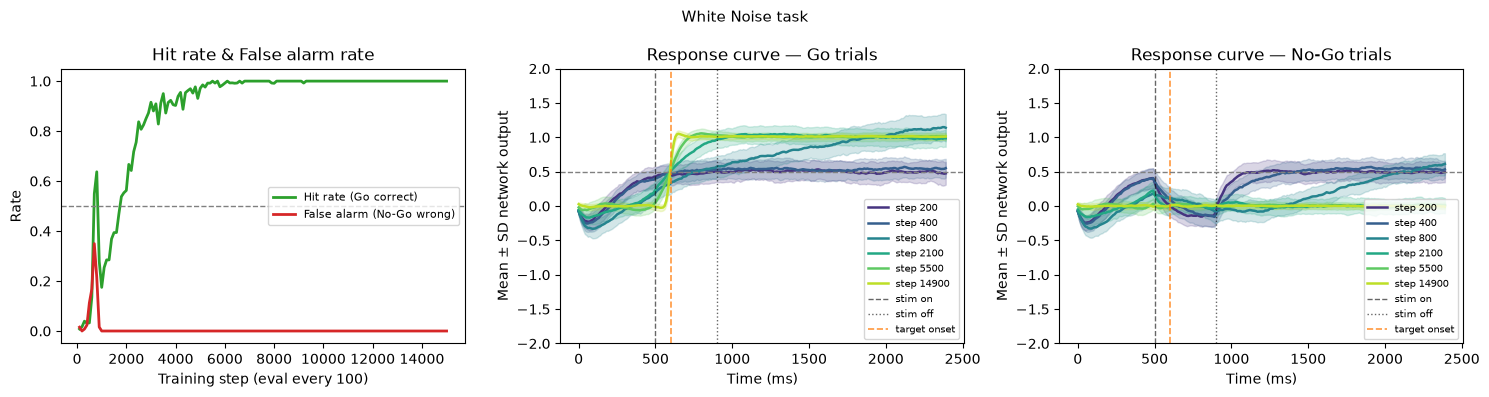

In [5]:
plot_training_log(cfg['save_path'], title='White Noise task', last_snap_step=15000);